Data Loading and Basic Exploration of the E. coli Dataset

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Column names from UCI dataset description
columns = ["sequence", "mcg", "gvh", "lip", "chg",
           "aac", "alm1", "alm2", "class"]

# Load dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/ecoli/ecoli.data"

data = pd.read_csv(url, sep=r"\s+", names=columns)

print("First 5 rows:")
print(data.head())

print("\nLast 5 rows:")
print(data.tail())

print("\nDataset Shape:")
print(data.shape)

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
print(data.describe())


First 5 rows:
     sequence   mcg   gvh   lip  chg   aac  alm1  alm2 class
0   AAT_ECOLI  0.49  0.29  0.48  0.5  0.56  0.24  0.35    cp
1  ACEA_ECOLI  0.07  0.40  0.48  0.5  0.54  0.35  0.44    cp
2  ACEK_ECOLI  0.56  0.40  0.48  0.5  0.49  0.37  0.46    cp
3  ACKA_ECOLI  0.59  0.49  0.48  0.5  0.52  0.45  0.36    cp
4   ADI_ECOLI  0.23  0.32  0.48  0.5  0.55  0.25  0.35    cp

Last 5 rows:
       sequence   mcg   gvh   lip  chg   aac  alm1  alm2 class
331  TREA_ECOLI  0.74  0.56  0.48  0.5  0.47  0.68  0.30    pp
332  UGPB_ECOLI  0.71  0.57  0.48  0.5  0.48  0.35  0.32    pp
333  USHA_ECOLI  0.61  0.60  0.48  0.5  0.44  0.39  0.38    pp
334  XYLF_ECOLI  0.59  0.61  0.48  0.5  0.42  0.42  0.37    pp
335  YTFQ_ECOLI  0.74  0.74  0.48  0.5  0.31  0.53  0.52    pp

Dataset Shape:
(336, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  

Q1. Count records in each localization class.

Protein Class Counts:
class
cp     143
im      77
pp      52
imU     35
om      20
omL      5
imL      2
imS      2
Name: count, dtype: int64


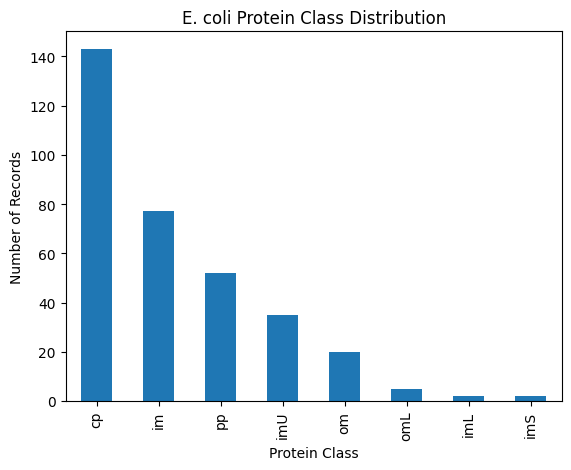

In [4]:

print("Protein Class Counts:")
print(data["class"].value_counts())

# Bar chart
data["class"].value_counts().plot(kind="bar")

plt.title("E. coli Protein Class Distribution")
plt.xlabel("Protein Class")
plt.ylabel("Number of Records")
plt.show()


Q2. Calculate mean, median, minimum and maximum for at least three numeric columns.

In [5]:

# Select three numeric columns
numbers = data[["mcg", "gvh", "aac"]].to_numpy()

print("Mean:", np.mean(numbers, axis=0))
print("Median:", np.median(numbers, axis=0))
print("Minimum:", np.min(numbers, axis=0))
print("Maximum:", np.max(numbers, axis=0))

print("\nColumn Order: mcg, gvh, aac")


Mean: [0.50005952 0.5        0.50002976]
Median: [0.5   0.47  0.495]
Minimum: [0.   0.16 0.  ]
Maximum: [0.89 1.   0.88]

Column Order: mcg, gvh, aac


Q3. Which localization class has the most records?

In [6]:

counts = data["class"].value_counts()

print("Class with most records:", counts.idxmax())
print("Number of records:", counts.max())


Class with most records: cp
Number of records: 143


Q4. Compare average values of two selected numeric columns across classes.

In [7]:

average = data.groupby("class")[["mcg", "gvh"]].mean()

print("Average MCG and GVH by Class:")
print(average)


Average MCG and GVH by Class:
            mcg       gvh
class                    
cp     0.363566  0.409720
im     0.478442  0.496623
imL    0.725000  0.470000
imS    0.740000  0.510000
imU    0.726000  0.458857
om     0.672500  0.710000
omL    0.698000  0.512000
pp     0.652115  0.699808


Q5. Find records with the highest values in a selected column

Top 5 Records with Highest AAC Values:
       sequence   mcg   gvh   lip  chg   aac  alm1  alm2 class
267  OMPX_ECOLI  0.77  0.57  0.48  0.5  0.88  0.53  0.20    om
265  OMPC_ECOLI  0.73  0.84  0.48  0.5  0.86  0.58  0.29    om
269   TSX_ECOLI  0.68  0.76  0.48  0.5  0.84  0.45  0.27    om
266  OMPF_ECOLI  0.75  0.76  0.48  0.5  0.83  0.57  0.30    om
259  FADL_ECOLI  0.78  0.68  0.48  0.5  0.83  0.40  0.29    om


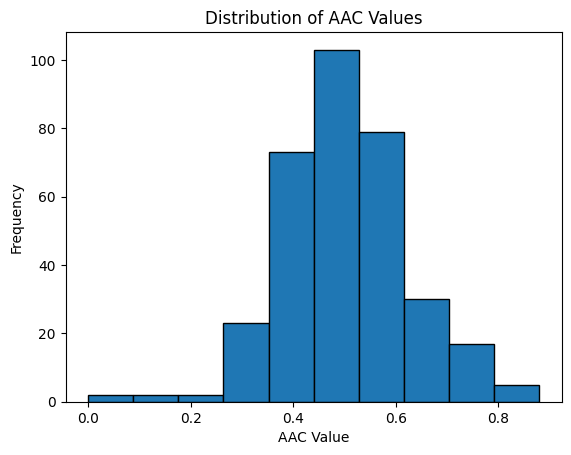

In [8]:

highest = data.sort_values("aac", ascending=False)

print("Top 5 Records with Highest AAC Values:")
print(highest.head(5))

# Histogram
plt.hist(data["aac"], bins=10, edgecolor="black")

plt.title("Distribution of AAC Values")
plt.xlabel("AAC Value")
plt.ylabel("Frequency")
plt.show()


Q6. Check for missing values and duplicates

In [9]:

print("Missing Values:")
print(data.isnull().sum())

print("\nDuplicate Records:")
print(data.duplicated().sum())

# Pandas filtering
print("\nRecords where MCG > 0.5:")
print(data[data["mcg"] > 0.5].head())


Missing Values:
sequence    0
mcg         0
gvh         0
lip         0
chg         0
aac         0
alm1        0
alm2        0
class       0
dtype: int64

Duplicate Records:
0

Records where MCG > 0.5:
      sequence   mcg   gvh   lip  chg   aac  alm1  alm2 class
2   ACEK_ECOLI  0.56  0.40  0.48  0.5  0.49  0.37  0.46    cp
3   ACKA_ECOLI  0.59  0.49  0.48  0.5  0.52  0.45  0.36    cp
5   ALKH_ECOLI  0.67  0.39  0.48  0.5  0.36  0.38  0.46    cp
13  CAIB_ECOLI  0.51  0.50  0.48  0.5  0.46  0.32  0.35    cp
22  CYNR_ECOLI  0.51  0.54  0.48  0.5  0.41  0.34  0.43    cp
